In [132]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [133]:
df_train =pd.read_csv(r"C:\Users\hp\Music\ml_classproject\practise_folder\regularization\train.csv")

In [134]:
df_train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [135]:
df_train =df_train.drop_duplicates()

In [136]:
df_train=df_train.drop(columns=["Cabin"])

<Axes: >

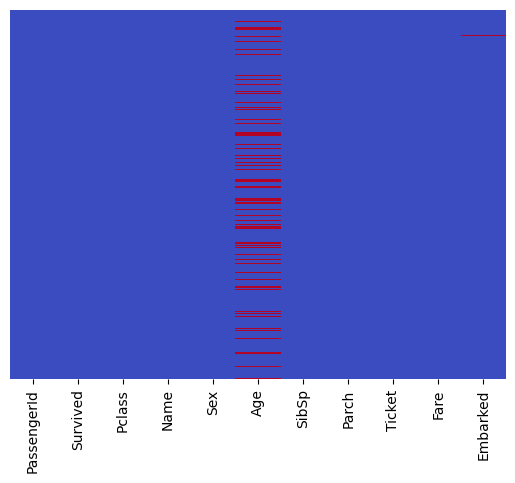

In [137]:
sns.heatmap(df_train.isnull(),yticklabels=False,cbar=False,cmap='coolwarm')

<Axes: xlabel='Survived', ylabel='count'>

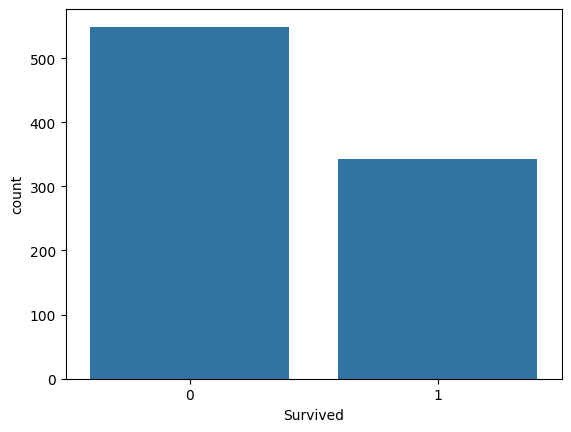

In [138]:
sns.countplot(df_train , x="Survived")

<Axes: xlabel='Pclass', ylabel='Age'>

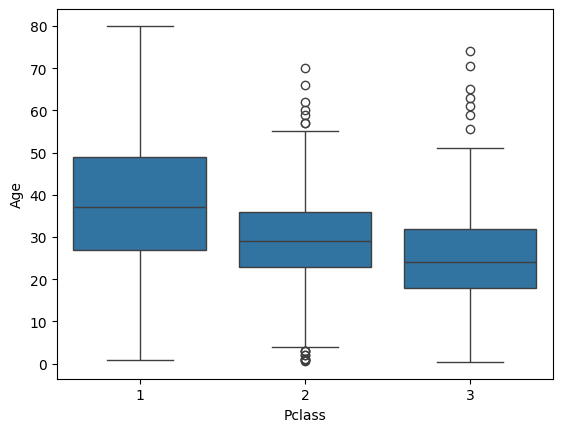

In [139]:
# datacleaning we need to fill the ,missing value of age we can do by suinf the mean method 
# but we can be smater 

sns.boxplot(x="Pclass" ,y="Age",data = df_train)

In [140]:
df_train["Embarked"] = df_train["Embarked"].fillna(df_train["Embarked"].mode()[0])


<Axes: >

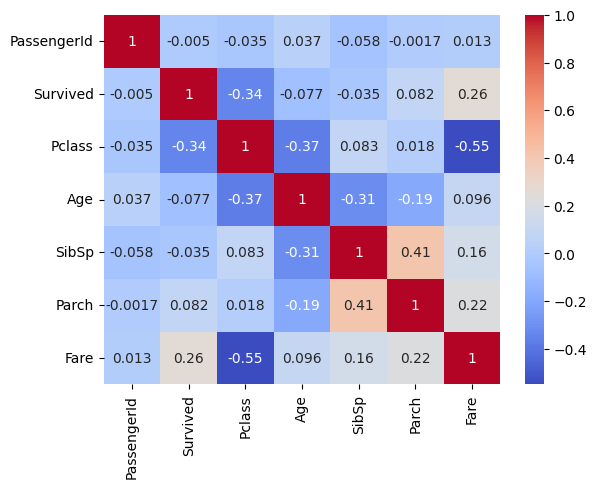

In [141]:
sns.heatmap(df_train.corr(numeric_only=True) ,annot=True ,cmap='coolwarm')

C:\Users\hp\AppData\Local\Temp\ipykernel_12732\4216655137.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df_train["Age"])


<Axes: xlabel='Age', ylabel='Density'>

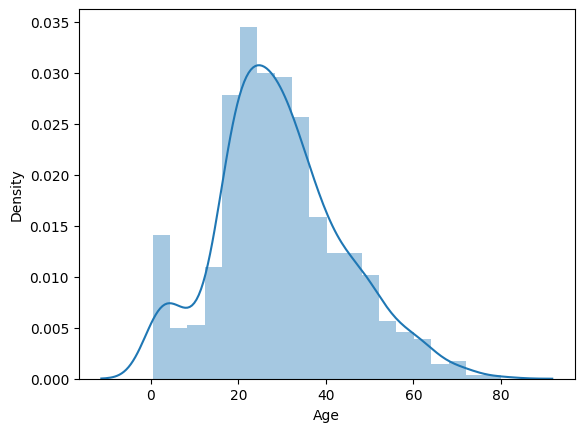

In [142]:
# check for any skwedness in the column distrubution
sns.distplot(df_train["Age"])

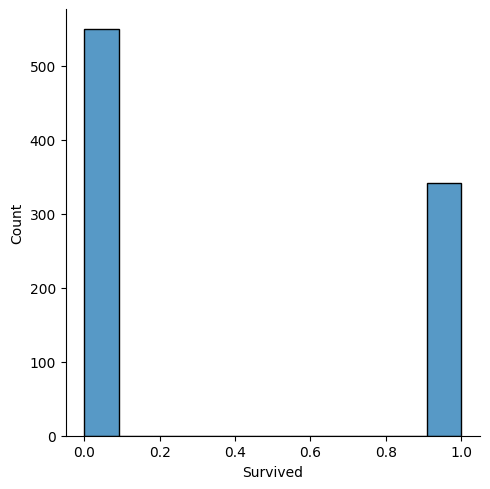

In [143]:
sns.displot(df_train["Survived"])

## converting categorical columns into numerical column 

In [144]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Embarked     891 non-null    str    
dtypes: float64(2), int64(5), str(4)
memory usage: 111.0 KB


In [145]:
df_train=pd.get_dummies(df_train,columns=["Sex"],drop_first=True)
df_train=pd.get_dummies(df_train ,columns=["Embarked"] ,drop_first=True)

In [146]:
df_train = df_train.drop(
    columns=[ "Name", "Ticket", "PassengerId"]
)

## model fitting in logistic regression


In [147]:
X = df_train.drop(columns=["Survived"])
y = df_train["Survived"]

In [148]:
X.isnull().sum()
X["Age"].fillna(X["Age"].mean(), inplace=True)

C:\Users\hp\AppData\Local\Temp\ipykernel_12732\1896247948.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  X["Age"].fillna(X["Age"].mean(), inplace=True)


0      22.000000
1      38.000000
2      26.000000
3      35.000000
4      35.000000
         ...    
886    27.000000
887    19.000000
888    29.699118
889    26.000000
890    32.000000
Name: Age, Length: 891, dtype: float64

In [149]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler 
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Split dataset
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

# Model
lr = LogisticRegression(max_iter=1000)

# Training
lr.fit(X_train, y_train)

# Prediction
y_pred = lr.predict(X_val)

# Evaluation
print("Accuracy:", accuracy_score(y_val, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_pred))


ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [ ]:
df_test = pd.read_csv(r"C:\Users\hp\Music\ml_classproject\practise_folder\regularization\test.csv")